# Arsenal probabilities: does league-wide training help?
## tl;dr
In the saved single-seed experiment, league-wide neural training reduced Arsenal test log loss from **0.960 to 0.900** across **75 matches**. The league-minus-Arsenal difference was **−0.060**, with a month-block bootstrap interval **[−0.101, −0.016]**. This is limited evidence for this model and historical sample, not a universal superiority claim. The logistic comparison was nearly tied on test.

The **league logistic baseline** was selected using validation alone. Neural test performance does not override that choice. All probabilities here are historical out-of-time estimates, not a forecast for a new fixture.

The saved outputs are viewable immediately. Set `RUN_TRAINING=True` below for a new bounded run; each run saves separate best checkpoints. Revisions after seeing these test results need a fresh holdout.

## Context & Methods
**Question:** predict Arsenal win/draw/loss using recent team/opponent performance and test whether league training improves predictions over Arsenal-only training.

**Protocol:** [EXPERIMENT_PROTOCOL.md](../EXPERIMENT_PROTOCOL.md). Train through 2021/22; select checkpoints on the same 74 Arsenal matches in 2022/23–2023/24; score the same 75 eligible Arsenal matches in 2024/25–2025/26. Default inputs are the 39 approved, strictly lagged features. No final-table metadata or current-match measurements enter X.

### Key assumptions
- Results of earlier matches become available before subsequent match dates. This is sequential forecasting, not a whole-season forecast made on opening day.
- Transfer means later non-Arsenal EPL fixtures. It does not mean unseen clubs or another league.
- Fine-tuning is prespecified and uses training data only; no test-informed architecture search.
- More league rows also mean more optimizer updates per epoch. Single seed; 100-epoch maximum may stop before convergence.
- Raw snapshots may have upstream errors. Reproducibility does not establish original-observer accuracy or rights.

### 1. Colab/local setup
In Colab, run this notebook from GitHub. Public cloning needs no token; if the repository is private, make an authenticated checkout using Colab's supported GitHub workflow or upload the repository first. Never paste credentials into notebook cells. The small MLP runs on CPU; no GPU is required.

Local setup: `python -m pip install -r requirements.txt` from the repository root. The first Colab cell installs the pinned requirements. If Colab asks to restart after package changes, restart and rerun.

In [1]:
from pathlib import Path
import os, sys, subprocess
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    PROJECT = Path('/content/Premier-League-Research')
    if not PROJECT.exists():
        subprocess.run(['git','clone','https://github.com/ryandai1/Premier-League-Research.git',str(PROJECT)],check=True)
    subprocess.run([sys.executable,'-m','pip','install','-q','-r',str(PROJECT/'requirements.txt')],check=True)
else:
    PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'experiments/train.py').exists())
os.chdir(PROJECT)
sys.path.insert(0,str(PROJECT))
RUN_TRAINING = False  # True creates a new run; never exceeds 100 epochs per fit.
CHECK_REMOTE_SOURCES = False  # Optional: recheck remote hashes without replacing snapshots.
print('Project:', PROJECT)

Project: /workspace/Premier-League-Research


In [2]:
import json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from experiments import audit, train
DATA = PROJECT/'arsenal_predictor_v1'
plt.rcParams.update({'figure.figsize':(10,4.5),'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'axes.grid':False})
BLUE='#236B8E'; GOLD='#B78126'; INK='#333333'
FIGURES=PROJECT/'results/figures';FIGURES.mkdir(exist_ok=True,parents=True)
def finish(name):
    plt.tight_layout();plt.savefig(FIGURES/f'{name}.png',dpi=140,bbox_inches='tight');plt.show()
raw=pd.read_csv(DATA/'raw/reza.csv',dtype={'Season':str})
display(raw[['Season','HomeTeam','AwayTeam','HomeGoal','AwayGoal']].head(5))
print('Source: frozen Reza CSV; exact URL/revision/hash in source_manifest.json.')

mkdir -p failed for path /home/agent/.config/matplotlib: [Errno 30] Read-only file system: '/home/agent/.config/matplotlib'


Matplotlib created a temporary cache directory at /tmp/matplotlib-8sc45mbg because there was an issue with the default path (/home/agent/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Fontconfig error: No writable cache directories


,Season,HomeTeam,AwayTeam,HomeGoal,AwayGoal
0,0001,Charlton,Man City,4,0
1,0001,Leeds,Everton,2,0
2,0001,Derby,Southampton,2,2
3,0001,Chelsea,West Ham,4,2
4,0001,Tottenham,Ipswich,3,1


Source: frozen Reza CSV; exact URL/revision/hash in source_manifest.json.


## Data
### 2. Visualize before cleaning
The source has 9,880 matches and 85 columns. Plot volume and missingness before accepting its README claims. Source: frozen `raw/reza.csv`; measurements and derived fields have different availability and semantics.

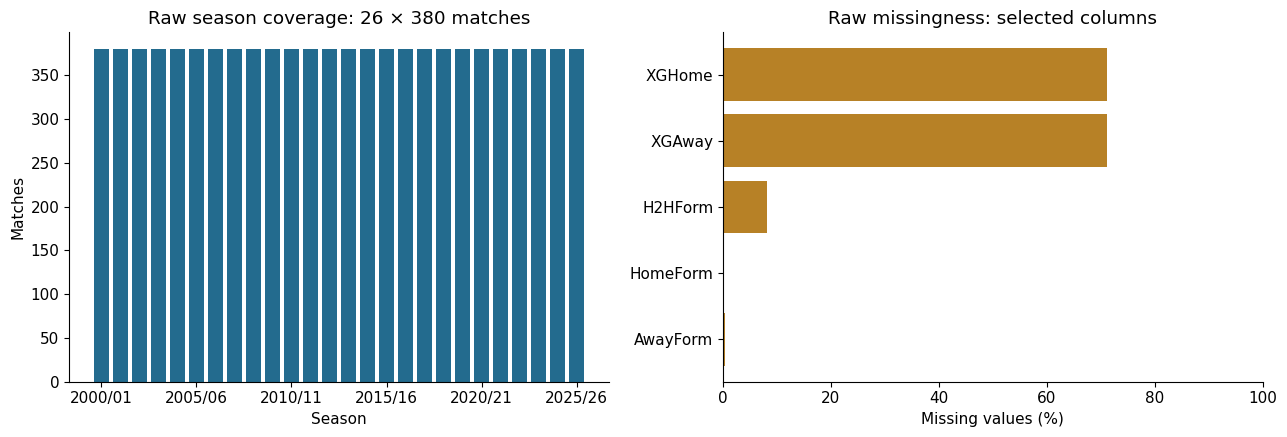

In [3]:
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
counts=raw.groupby('Season').size();axes[0].bar(np.arange(len(counts)),counts,color=BLUE)
axes[0].set_xticks([0,5,10,15,20,25],['2000/01','2005/06','2010/11','2015/16','2020/21','2025/26'])
axes[0].set(title='Raw season coverage: 26 × 380 matches',ylabel='Matches',xlabel='Season')
cols=['XGHome','XGAway','H2HForm','HomeForm','AwayForm'];missing=raw[cols].isna().mean()*100
axes[1].barh(cols,missing,color=GOLD);axes[1].set(xlabel='Missing values (%)',title='Raw missingness: selected columns',xlim=(0,100));axes[1].invert_yaxis()
finish('01_raw_profile')

### 3. Apply the documented cleaning and audit protocol
The bundle already contains cleaned tables. We verify them rather than repeatedly editing raw evidence. Aliases/dates are standardized; duplicate fixtures fail; five contradictory shot-stat sides become missing; xG remains optional; no missing labels are invented. All original matches remain archived, while rows lacking five valid prior observations are excluded from default training.

The audit independently checks split alignment and replays the supplied feature definitions. It logs **57 corrected metadata cells** in a separate table (Bolton goal differences and W/D/L totals). Those fields never enter the model. Original raw bytes and the original release checksum manifest remain intact. Original validation reports are historical; the following output is the current audit.

In [4]:
verification=audit.run()
display(pd.Series(verification))
corrections=pd.read_csv(PROJECT/'results/audit/metadata_corrections.csv')
display(corrections.groupby(['column','old','new','basis']).size().rename('affected_records').reset_index())
if CHECK_REMOTE_SOURCES:
    from experiments.check_sources import run as check_sources
    display(pd.DataFrame(check_sources())[['name','status']])

passed                                                                              True
matches                                                                             9880
reproduced_features                                                                 9880
correction_cells                                                                      57
raw_preserved                                                                       True
remote_football_data_verified                                                      False
original_provider_per_cell_verified                                                False
checks                                 [raw SHA256, raw-to-clean equality, season cou...
dtype: object

,column,old,new,basis,affected_records
0,SeasonGDAway,-19.0,-12.0,GF minus GA; algebraic repair only,19
1,SeasonGDHome,-28.0,-18.0,GF minus GA; algebraic repair only,19
2,SeasonWinAway,8.0,9.0,Recomputed from frozen season match results,19


### 4. Visualize after cleaning
Eligibility is not deletion: 441 archived fixtures lack sufficient valid history. Missing shot values may also exclude later history windows. This favors established teams and excludes some promoted-team/opening-season cases. No synthetic augmentation is used.

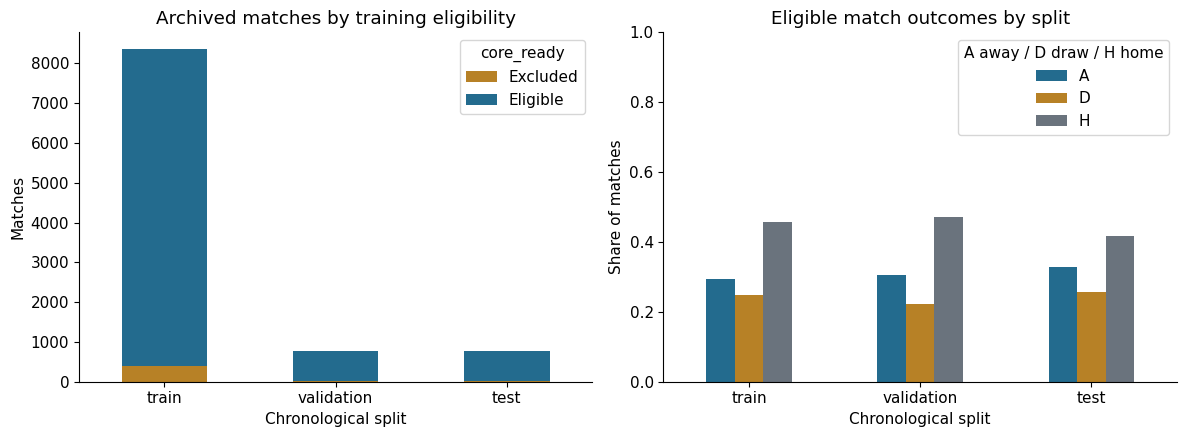

split
train         7977
validation     730
test           732
Name: eligible_matches, dtype: int64

In [5]:
full=pd.read_csv(DATA/'data/prematch_all.csv')
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
coverage=pd.crosstab(full['split'],full.core_ready).reindex(['train','validation','test'])
coverage.rename(columns={False:'Excluded',True:'Eligible'}).plot.bar(stacked=True,ax=axes[0],color=[GOLD,BLUE],rot=0)
axes[0].set(title='Archived matches by training eligibility',ylabel='Matches',xlabel='Chronological split')
ready=full[full.core_ready];balance=pd.crosstab(ready.split,ready.target_result,normalize='index').reindex(['train','validation','test'])
balance[['A','D','H']].plot.bar(ax=axes[1],rot=0,color=[BLUE,GOLD,'#6A737D'])
axes[1].set(title='Eligible match outcomes by split',ylabel='Share of matches',xlabel='Chronological split',ylim=(0,1))
axes[1].legend(title='A away / D draw / H home')
finish('02_cleaned_profile')
display(ready.groupby('split').size().rename('eligible_matches').reindex(['train','validation','test']))

### 5. Train or inspect the saved experiment
Three MLP fits use AdamW, learning rate 1e-4, weight decay 0.01, seed 42, batch 256, maximum 100 epochs, patience 20. Each new minimum saves a best checkpoint. Fine-tuning starts from the frozen league checkpoint and retains its scaler; epoch zero may win. Training logs contain both train and Arsenal validation loss.

The two logistic baselines and class-prior baseline prevent neural complexity from being mistaken for improvement. Checkpoint selection uses validation only. Saved results are rejected if input/code hashes or configuration differ.

In [6]:
if RUN_TRAINING:
    RUN=train.run()
else:
    runs=sorted((PROJECT/'results').glob('run_*'))
    if not runs:raise RuntimeError('No saved run: set RUN_TRAINING=True.')
    RUN=runs[-1]
manifest=json.loads((RUN/'run_manifest.json').read_text())
assert manifest['config']==train.CONFIG
assert manifest['code_sha256']==train.digest(PROJECT/'experiments/train.py')
for name,expected in manifest['input_sha256'].items():
    assert train.digest(DATA/'data'/name)==expected, name
training=pd.read_csv(RUN/'training_summary.csv')
assert training.epochs_run.le(100).all()
display(training[['model','training_rows','best_epoch','epochs_run','validation_arsenal_log_loss']])
selection=json.loads((RUN/'selected_model.json').read_text())
print('Validation-selected candidate:',selection['selected_model'])
print('Run:',RUN.name)

,model,training_rows,best_epoch,epochs_run,validation_arsenal_log_loss
0,league_mlp,7977,98,100,0.796609
1,arsenal_mlp,815,100,100,0.864435
2,league_to_arsenal_mlp,815,1,21,0.796373


Validation-selected candidate: league_logistic
Run: run_20261024T140407


## Results
### 6. Inspect learning curves and saved optimal parameters
Vertical lines mark the saved best epoch; the final epoch is not automatically the chosen model. The first two runs reached the cap, while fine-tuning stopped after 20 epochs without material improvement. “Best” means best observed validation checkpoint under this fixed budget, not a globally optimal model.

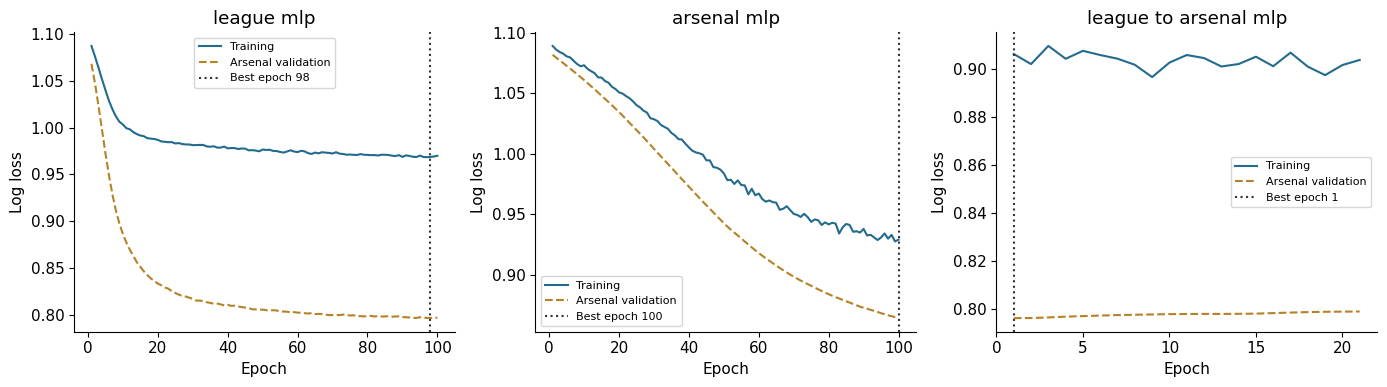

In [7]:
fig,axes=plt.subplots(1,3,figsize=(14,4))
for ax,row in zip(axes,training.itertuples()):
    h=pd.read_csv(RUN/f'{row.model}_history.csv')
    ax.plot(h.epoch,h.training_log_loss,label='Training',color=BLUE)
    ax.plot(h.epoch,h.validation_arsenal_log_loss,label='Arsenal validation',color=GOLD,linestyle='--')
    ax.axvline(row.best_epoch,color=INK,linestyle=':',label=f'Best epoch {row.best_epoch}')
    ax.set(title=row.model.replace('_',' '),xlabel='Epoch',ylabel='Log loss');ax.legend(fontsize=8)
finish('03_learning_curves')

In [8]:
# Reload each checkpoint and verify its predictions match the frozen exported predictions.
import torch
schema=json.loads((DATA/'feature_schema.json').read_text())
x_test=pd.read_csv(DATA/'data/test/X.csv')
for row in training.itertuples():
    path=RUN/f'{row.model}_best.pt'
    assert train.digest(path)==row.checkpoint_sha256
    ck=torch.load(path,map_location='cpu',weights_only=False)  # trusted project checkpoint only
    assert ck['epoch']==row.best_epoch and ck['features']==schema['features']
    restored=train.predict_checkpoint(path,x_test)
    saved=pd.read_csv(RUN/f'{row.model}_test_predictions.csv')
    np.testing.assert_allclose(restored.to_numpy(),saved[['p_A','p_D','p_H']].to_numpy(),rtol=1e-5,atol=1e-7)
    print(row.model, 'reload passed; best epoch', ck['epoch'], '; AdamW lr',ck['config']['lr'])

league_mlp reload passed; best epoch 98 ; AdamW lr 0.0001
arsenal_mlp reload passed; best epoch 100 ; AdamW lr 0.0001
league_to_arsenal_mlp reload passed; best epoch 1 ; AdamW lr 0.0001


### 7. Compare models on identical Arsenal fixtures
Primary metric: log loss, lower is better. Multiclass Brier score is the sum across three classes, not the average. Accuracy is secondary because the objective is probability quality. The main hypothesis compares the first two MLPs; fine-tuning and baselines are supporting comparisons.

,model,log_loss,brier_multiclass,accuracy,n
18,league_mlp,0.8999,0.5291,0.6133,75
21,arsenal_mlp,0.9597,0.5690,0.6000,75
24,league_to_arsenal_mlp,0.9004,0.5294,0.6133,75
27,league_logistic,0.9090,0.5326,0.6133,75
30,arsenal_logistic,0.9093,0.5344,0.6400,75
33,league_prior,1.0944,0.6642,0.4000,75


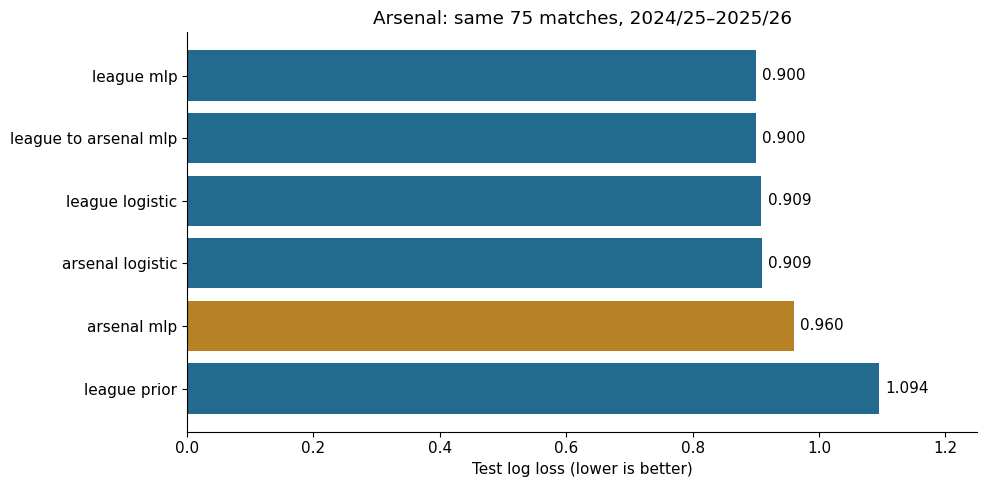

comparison                                      league_mlp minus arsenal_mlp Arsenal test log ...
difference                                                                              -0.059782
month_block_bootstrap_95_percentile_interval         [-0.10078658796846866, -0.01619370488915595]
resamples                                                                                    1000
blocks                                                                                         20
caveat                                          Single training seed; short historical test; i...
dtype: object

In [9]:
metrics=pd.read_csv(RUN/'metrics.csv')
test=metrics[(metrics.split=='test')&metrics.population.eq('Arsenal')].copy()
display(test[['model','log_loss','brier_multiclass','accuracy','n']].round(4))
fig,ax=plt.subplots(figsize=(10,5))
ordered=test.sort_values('log_loss');bars=ax.barh(ordered.model.str.replace('_',' '),ordered.log_loss,color=[GOLD if n=='arsenal_mlp' else BLUE for n in ordered.model]);ax.invert_yaxis()
for bar,value in zip(bars,ordered.log_loss):ax.text(value+.01,bar.get_y()+bar.get_height()/2,f'{value:.3f}',va='center')
ax.set(xlim=(0,1.25),xlabel='Test log loss (lower is better)',title='Arsenal: same 75 matches, 2024/25–2025/26')
finish('04_arsenal_comparison')
comparison=json.loads((RUN/'comparison.json').read_text())
display(pd.Series(comparison))

The saved MLP comparison favors league training, but the logistic comparison is nearly tied. The bootstrap resamples 20 calendar-month blocks and does not include random-seed uncertainty. It is not evidence that every model benefits from league training. Fine-tuning shows no meaningful practical improvement in this run.

### 8. Frozen transfer and calibration
Inspect non-Arsenal EPL test performance without training on those test outcomes. Population differences make these scores unsuitable as direct estimates of performance in another league. Calibration is shown for Arsenal win probability using fixed bins; sparse bins are unstable.

,model,log_loss,brier_multiclass,accuracy,n
19,league_mlp,1.0324,0.6211,0.4779,657
22,arsenal_mlp,1.0393,0.6253,0.5053,657
25,league_to_arsenal_mlp,1.0325,0.6212,0.4779,657
28,league_logistic,1.0290,0.6192,0.4916,657
31,arsenal_logistic,1.1015,0.6574,0.4779,657
34,league_prior,1.0816,0.6556,0.4186,657


league_mlp calibration bin counts: [2, 5, 14, 49, 5]
arsenal_mlp calibration bin counts: [1, 12, 37, 18, 7]


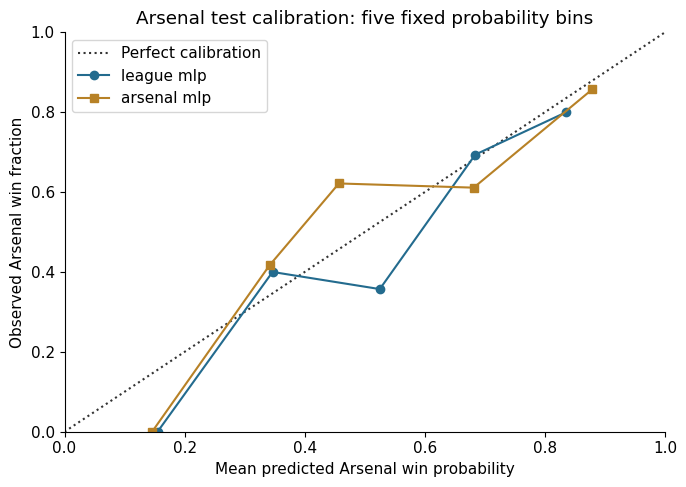

In [10]:
display(metrics[(metrics.split=='test')&metrics.population.eq('Other EPL')][['model','log_loss','brier_multiclass','accuracy','n']].round(4))
fig,ax=plt.subplots(figsize=(7,5));ax.plot([0,1],[0,1],':',color=INK,label='Perfect calibration')
for name,color,marker in [('league_mlp',BLUE,'o'),('arsenal_mlp',GOLD,'s')]:
    p=pd.read_csv(RUN/f'{name}_test_arsenal_probabilities.csv')
    p['win']=((p.home_team.eq('Arsenal')&p.target_class.eq('H'))|(p.away_team.eq('Arsenal')&p.target_class.eq('A'))).astype(int)
    p['bin']=pd.cut(p.p_win,np.linspace(0,1,6),include_lowest=True)
    cal=p.groupby('bin',observed=True).agg(predicted=('p_win','mean'),observed=('win','mean'),n=('win','size'))
    ax.plot(cal.predicted,cal.observed,marker=marker,color=color,label=name.replace('_',' '))
    print(name, 'calibration bin counts:', cal.n.to_list())
ax.set(xlim=(0,1),ylim=(0,1),xlabel='Mean predicted Arsenal win probability',ylabel='Observed Arsenal win fraction',title='Arsenal test calibration: five fixed probability bins');ax.legend()
finish('05_calibration')

### 9. Inspect Arsenal win/draw/loss probabilities
The table shows the last ten historical test fixtures for the validation-selected candidate. Away-match orientation is explicitly converted: Arsenal win = away-win probability when Arsenal is away. The full CSV includes all eligible test fixtures and is saved with each model.

In [11]:
probs=pd.read_csv(RUN/f"{selection['selected_model']}_test_arsenal_probabilities.csv")
assert np.allclose(probs[['p_win','p_draw','p_loss']].sum(axis=1),1,atol=1e-6)
display(probs[['date','home_team','away_team','p_win','p_draw','p_loss']].tail(10).round(3))

,date,home_team,away_team,p_win,p_draw,p_loss
65,2026-03-01,Arsenal,Chelsea,0.685,0.182,0.133
66,2026-03-04,Brighton,Arsenal,0.520,0.233,0.247
67,2026-03-14,Arsenal,Everton,0.742,0.161,0.097
68,2026-04-11,Arsenal,Bournemouth,0.733,0.144,0.122
69,2026-04-19,Manchester City,Arsenal,0.304,0.215,0.481
70,2026-04-25,Arsenal,Newcastle,0.750,0.144,0.106
71,2026-05-02,Arsenal,Fulham,0.711,0.158,0.131
72,2026-05-10,West Ham,Arsenal,0.663,0.184,0.153
73,2026-05-18,Arsenal,Burnley,0.848,0.118,0.034
74,2026-05-24,Crystal Palace,Arsenal,0.583,0.210,0.207


## Takeaways
**Claim:** under this prespecified, single-seed MLP setup, league-wide training improved held-out Arsenal probability quality relative to Arsenal-only training.

**Supporting figure:** the identical-fixture test comparison, with paired log-loss difference and month-block interval above.

**Limitation:** 75 eligible Arsenal test matches, one training seed, related upstream sources and no external-league test. The two initial neural runs hit the cap. Logistic baselines did not show a comparable gain. Do not generalize the conclusion to all models or competitions.

**Next experiment:** prespecify multiple seeds or a recent-history ablation using new rolling evaluation periods; do not revise the framework using this test and present a repeated score as fresh confirmation. No architecture search or extra training is automatically launched.

**Remaining data limits:** original-provider attribution per observation and upstream reuse rights are unresolved. Live football-data hashes were proxy-blocked in the cloud audit. The optional source check can test these from Colab without silently updating snapshots. No 2026/27 data or live scoring feed is included.

Sources: the bundled source manifest, pinned Reza/Tara CSVs, three bundled football-data snapshots, row lineage and correction ledger. Hugging Face was discovery/documentation only.

### 10. Preserve a new Colab run
Colab runtimes are temporary. This cell makes a portable ZIP of the run and figures. Enable download or copy to your own Drive before ending a fresh runtime. GitHub is not automatically updated by running this notebook.

In [12]:
import shutil
export_base=Path('/tmp')/f'{RUN.name}_artifacts'
import zipfile
archive=str(export_base)+'.zip'
with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED) as bundle:
    for path in list(RUN.rglob('*'))+list(FIGURES.glob('*.png')):
        if path.is_file():bundle.write(path,str(path.relative_to(PROJECT/'results')))
print('Run archive:',archive)
DOWNLOAD_RUN = False
if IN_COLAB and DOWNLOAD_RUN:
    from google.colab import files
    files.download(archive)

Run archive: /tmp/run_20261024T140407_artifacts.zip
